# Persistent object graph explorer

Interactive inline Plotly views work on a headless cluster; no desktop or browser is launched on the server. Use the EAI project Python kernel. Run the scene pipeline once before opening this notebook. All rebuilds below use cached SAM masks, DINO/SigLIP descriptors and 3D boxes; graph replay loads no models. Text search loads only the SigLIP encoder on the first search.

Frame selection replays memory up to that frame, including objects currently out of view. Object selection shows representative observations across the full sequence. Score tables show pre-update scores for the selected match, or the best compatible rejected candidate for a new node. The first observation has no candidate. Spatial edges are geometric approximations, not contact/support assertions.

In [1]:
from pathlib import Path
import sys

ROOT = Path.cwd()
if not (ROOT / 'src').exists():
    ROOT = ROOT.parent
assert (ROOT / 'src').exists(), 'Open this notebook from the repository or notebooks directory'
sys.path.insert(0, str(ROOT / 'src'))

import plotly.io as pio
pio.renderers.default = 'plotly_mimetype'
from graph.association import AssociationConfig
from graph.pipeline import DEFAULT_CONFIG
from graph.visualize import GraphExplorer
from utils.schema import Run

In [2]:
# Change these to select a cached run. GT depth/poses are the baseline.
run = Run(source='replica/room_0/00', stride=20, mask_source='sam3', pose_source='gt')
config_path = DEFAULT_CONFIG
config = AssociationConfig.from_json(config_path)
explorer = GraphExplorer(run, config)
print('Cached observation rows:', len(explorer.data[0].frame))
print('Persistent objects:', len(explorer.result.memory.nodes))
print('Normalized weights:', config.effective_weights)

Cached observation rows: 4090
Persistent objects: 224
Normalized weights: (0.45, 0.15, 0.4)


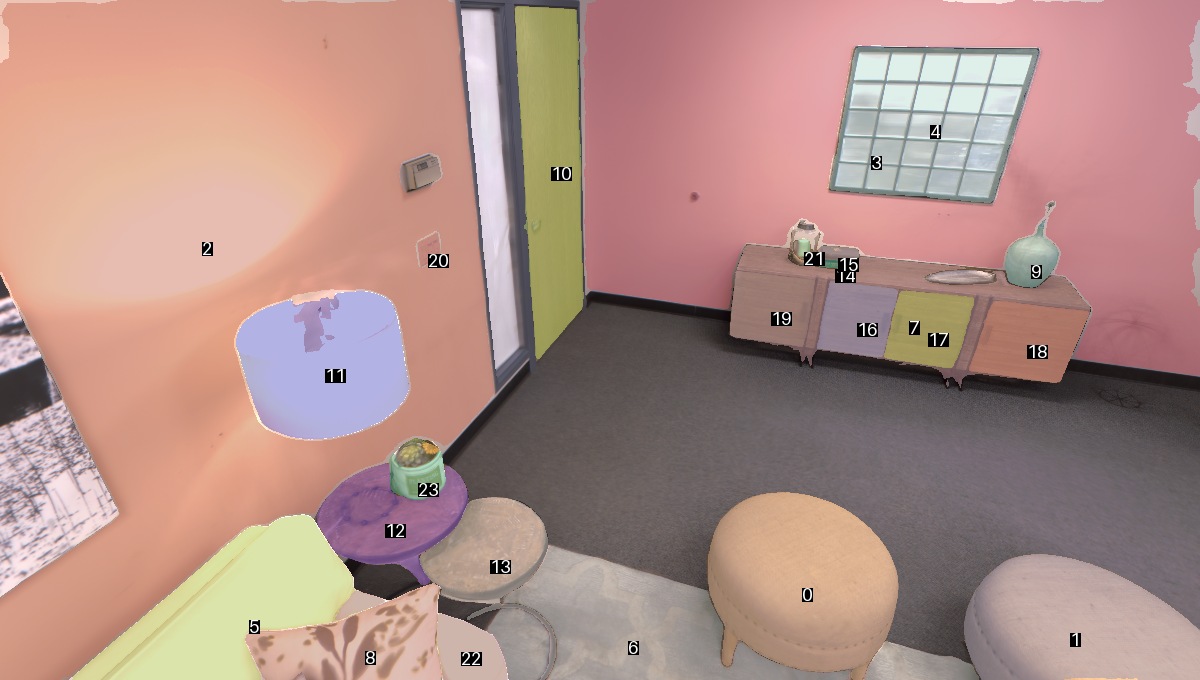

In [3]:
# A standard inline PNG preview works even without a Plotly renderer.
from IPython.display import Image, display
from graph.visualize import overlay_png

first_frame = int(explorer.frames[0])
display(Image(data=overlay_png(run, explorer.data[0], explorer.result.graph.node, first_frame), width=1000))

Adjust weights, switches and threshold, then click **Rebuild from cache**. Raw weights are normalized over enabled components; missing/invalid cues contribute zero without redistributing their weight. Cosines are clipped to [0,1]. Geometry blends unpadded IoU and exp(-center distance / scale). The spatial gate applies whenever both boxes are valid, even if geometry scoring is disabled.

Rebuilding is in memory until you click **Save graph + config**, which replaces only graph artifacts, not the descriptor or geometry caches. Prefix replay may take a few seconds. A growing node count may indicate fragmentation; lowering the threshold can instead create incorrect merges. Compare identity/revisit metrics before accepting a setting.

**Text search:** type `chair`, `striped pillow`, or another description in **Search**, then click **Find objects**. The top five remembered objects are ranked by SigLIP cosine similarity. The best result is selected automatically; choosing another match updates the object and frame views. Search uses cached image descriptors, so SAM, DINO and image embedding inference are not rerun. Scores rank candidates and do not guarantee that the requested object exists.

In [4]:
explorer.widgets()

Optional identity evaluation against Replica ground truth. GT masks and events must already be cached by run.py. This does not require a text encoder or GPU inference.

In [5]:
from dataclasses import replace
sys.path.insert(0, str(ROOT))
import evaluate
from utils import replica
from utils.schema import Events, Masks, load_stage

gt_run = replace(run, mask_source='gt', vocab='')
if gt_run.done('masks') and run.done('events'):
    gt = load_stage(gt_run.stage_dir('masks'), Masks)
    events = load_stage(run.stage_dir('events'), Events)
    scene, _ = replica.parse_source(run.source)
    metrics = evaluate.evaluate(explorer.data[0], explorer.result.graph.node, gt, events, replica.load_objects(scene))
    print(metrics)
else:
    print('Run run.py on this scene first to prepare GT evaluation caches.')

{'idf1': 0.610435758369179, 'idp': 0.5816108339272986, 'idr': 0.6422668240850059, 'ids': 224, 'ids_per_object': 1.9791666666666667, 'objects_per_id': 1.130952380952381, 'revisits': 84, 'kept': 45, 'switched': 12, 'missed': 27, 'kept_rate': 0.7894736842105263}
